In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from windrose import WindroseAxes
import foxes
import foxes.variables as FV
from pathlib import Path
from foxes import ModelBook


c:\Users\HP\miniforge3\envs\foxes\Lib\site-packages\foxes\core\engine.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
df = pd.read_csv('reanalysis/reanalysis_2006.csv')
print(df.head())

             Date_time  WS100  WD100
0  2006-01-01 00:00:00  8.515  243.1
1  2006-01-01 01:00:00  8.379  246.2
2  2006-01-01 02:00:00  7.772  245.6
3  2006-01-01 03:00:00  7.852  241.6
4  2006-01-01 04:00:00  8.319  239.5


In [3]:
dt_index = pd.to_datetime(df["Date_time"], utc=True)
df = df.set_index(dt_index)
df.index.name = "Date_time"
df = df.sort_index()
df = df.drop(columns=["Date_time"])
print(df.head())

                           WS100  WD100
Date_time                              
2006-01-01 00:00:00+00:00  8.515  243.1
2006-01-01 01:00:00+00:00  8.379  246.2
2006-01-01 02:00:00+00:00  7.772  245.6
2006-01-01 03:00:00+00:00  7.852  241.6
2006-01-01 04:00:00+00:00  8.319  239.5


In [4]:
print(len(df) - (365*24))

0


In [5]:
print(np.sum(df.index.duplicated()))

0


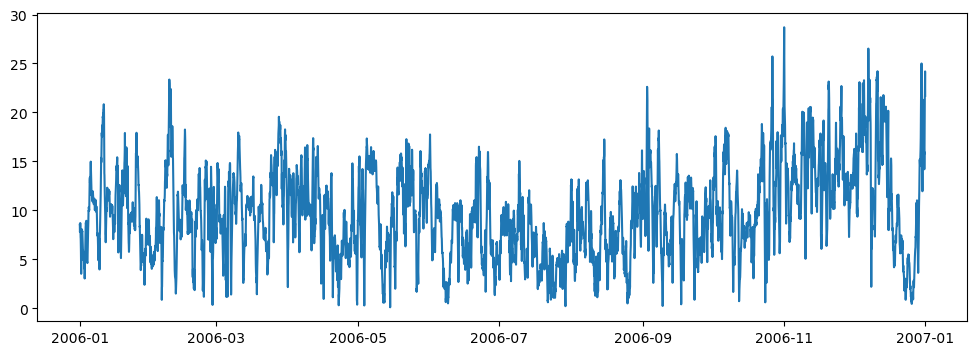

In [6]:
plt.figure(figsize=(12,4))
plt.plot(df['WS100'])
plt.show()

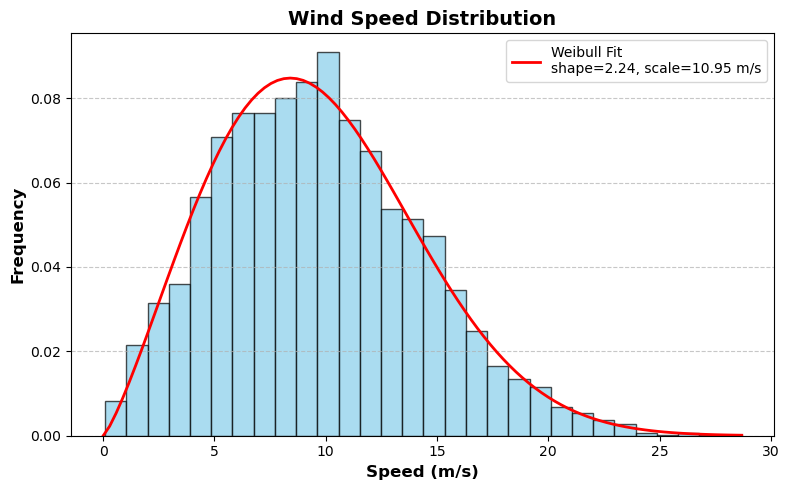

In [7]:
shape, loc, scale = stats.weibull_min.fit(df['WS100'], floc=0)

plt.figure(figsize=(8, 5))
plt.hist(df['WS100'], bins=30, density=True, color='skyblue', edgecolor='black', alpha=0.7)

x = np.linspace(0, max(df['WS100']), 100)
plt.plot(x, stats.weibull_min.pdf(x, shape, loc, scale), 'r-', lw=2, label=f'Weibull Fit\nshape={shape:.2f}, scale={scale:.2f} m/s')

plt.title('Wind Speed Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Speed (m/s)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

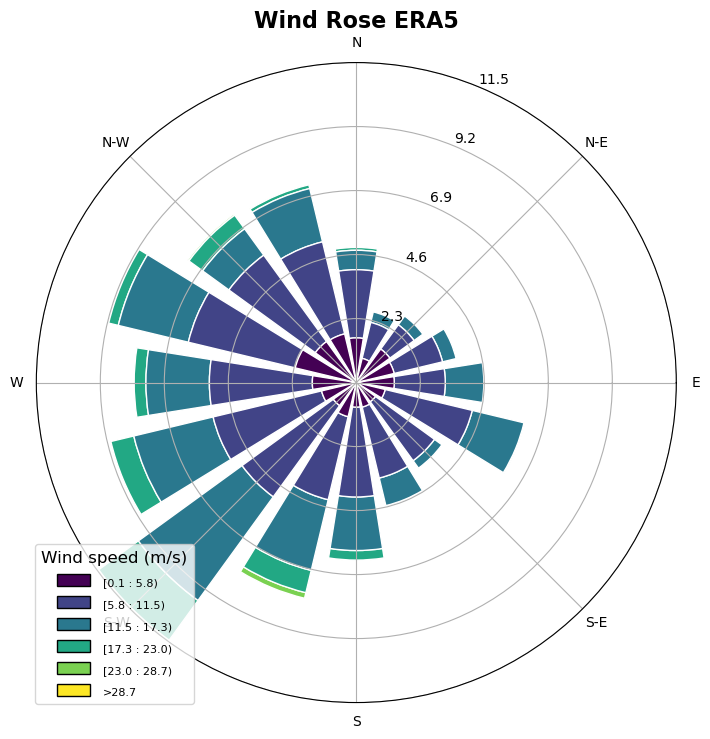

In [8]:
fig = plt.figure(figsize=(8, 8))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    df['WD100'],
    df['WS100'],
    normed=True,
    opening=0.8,
    edgecolor="white"
)

ax.set_legend(title="Wind speed (m/s)", fontsize=12, title_fontsize=12)
ax.set_title("Wind Rose ERA5",fontsize=16, fontweight="bold")
plt.show()

# Task 3: Yield of the Areas N-10.1/N-10.2 Without External Wake Effects

In [23]:
# Step 1: Load ERA5 Data as States
latitude = 54.602
longitude = 6.145
states = foxes.input.states.Timeseries(
    data_source = Path("reanalysis/reanalysis_2006.csv"),
    output_vars = [FV.WS, FV.WD, FV.TI, FV.RHO],
    var2col={FV.WS: "WS100", FV.WD: "WD100"},
    fixed_vars={FV.TI: 0.05, FV.RHO: 1.225},  
  # log-law extrapolation to hub height 
    read_pars={"dayfirst": True}
)

# Step 2: Set Up turbine type
mbook = foxes.ModelBook()
mbook.turbine_types["IEA15MW"] = foxes.models.turbine_types.PCtFile(
    Path("./turbine-info/power_curves/IEA-15MW-D240-H150.csv").resolve(strict=True),
    col_ws="ws", 
    col_P="P",
    col_ct="ct",
    D=240.0,
    H=150.0,
    P_nominal=15000,
    P_unit="kW",
    rho=1.225
)

# step 3: Wind Farm Layout
farm = foxes.WindFarm(name="N-10.1")
layout1 = Path("./turbine-info/area_of_interest/layout-N-10.1.geom.csv").resolve(strict=True)
foxes.input.farm_layout.add_from_file(
    farm,
    layout1,
    col_x="x",
    col_y="y",
    turbine_models=["IEA15MW"],
    verbosity=0
)

# Step 4: Algorithm setup for no wake models

algorithm = foxes.algorithms.Downwind(
    farm,
    states,
    wake_models=[],
    mbook=mbook,
    verbosity=0
)

# Step 5: Run the foxes
engine = foxes.Engine.new("process", chunk_size_states=500)
with engine:
    results = algorithm.calc_farm()

# Step 6: Compute Energy Yield
out = foxes.output.FarmResultsEval(results)

# # Per-turbine yield over the ERA5 period (GWh):  


ProcessEngine: Calculating 8760 states for 133 turbines
ProcessEngine: Starting calculation using 3 workers, for 18 states chunks.


  0%|          | 0/18 [00:00<?, ?it/s]

ProcessEngine: Completed all 18 chunks



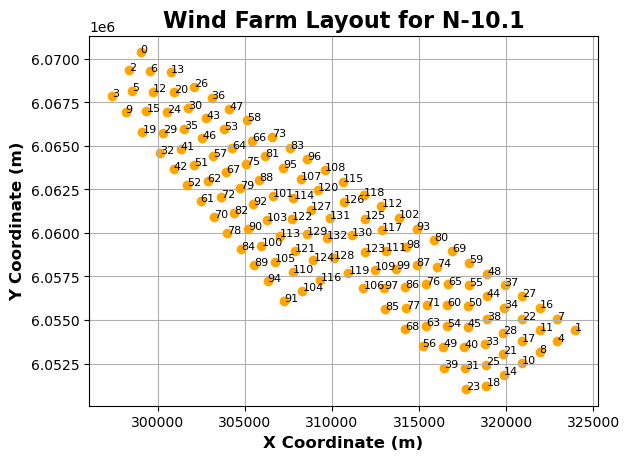

In [27]:
plt.Figure(figsize=(8, 10))
foxes.output.FarmLayoutOutput(farm).get_figure()
plt.title("Wind Farm Layout for N-10.1", fontsize=16, fontweight="bold")
plt.xlabel("X Coordinate (m)", fontsize=12, fontweight="bold")
plt.ylabel("Y Coordinate (m)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [35]:
#turbine_yield = out.calc_turbine_yield(algo=algorithm, annual=True)  
#print(turbine_yield)  
  
# # Total farm yield, annualized (GWh/year):  
farm_yield_gwh = out.calc_farm_yield(algo=algorithm, annual=True)  
print(f"Annual farm yield: {farm_yield_gwh:.2f} GWh")

Annual farm yield: 10632.19 GWh
